# Provision of Chemicals II

### hier Ihr MIP
The pharmaceutical company Boring International wants to optimize the supply of chemical raw materials from an external warehouse to its company premises. Each day is divided into certain time periods. During each time period, there may be a demand for a specific raw material at the company premises. To meet this demand, trucks operate between the external warehouse and the company premises. Raw materials transported by a truck can either be used directly to satisfy the demand or stored temporarily to meet demand at a later time. The temporary storage facility has limited storage capacity, and each truck also has a limited transport capacity.

Each trip incurs a cost. These costs are to be minimized.

NEW Multiple trucks are available.

The external warehouse is located further away:

Each truck requires $r$ time periods to complete a round trip from the company premises to the external warehouse and back. This means that there must be at least $r$ time periods between two deliveries made by the same truck. In addition, there are raw materials that must not be transported together in the same truck (e.g., hydrogen and oxygen), for example, because this could pose an explosion hazard in the event of an accident.

Each instance is characterized by the following data:

- The set of raw materials (chemicals): $\mathcal C$
- Capacity of the temporary storage facility: $B$
- The time periods: $0,...,T-1$
- Demand for raw material $c$ at time $t$: $d_{ct}$
- Duration of a transport trip: $r$
- Cost per trip: $g$
- Capacity of the delivery trucks: $h$
- Number of delivery trucks: $k$
- Set of pairs of raw materials that must not be transported together: $\mathcal I$

Variables:
* $z_{tv}\in\{0,1\}$: Inidcates whether a deliver with truck $v$ takes place at time $t$
* $x_{ctv}\geq 0$: Amount of material $c$ that is being delivered in truck $v$ at time $t$
* $y_{ctv}\in\{0,1\}$: Indicates whether truck $v$ is delivering material $c$ in the beginning of time period $t$
* $p_{ct}\geq 0$: Amount of material $c$ that is stocked in the temporary storage facility at the end of time period $t$

We load the necessary files and perform two required `import` statements. The output may look complicated — simply ignore it\! If you are working locally on your computer, have mip installed, and have placed chm.py in the same directory, comment out the first two lines.

In [9]:
!wget -q https://raw.githubusercontent.com/henningbruhn/mobp/main/chem_aufgabe/chm.py
!pip install mip

import mip   ## Der mip-solver
import chm   ## Code zur Instanzenerzeugung und zur graphischen Darstellung

error: externally-managed-environment

× This environment is externally managed
╰─> To install Python packages system-wide, try apt install
    python3-xyz, where xyz is the package you are trying to
    install.
    
    If you wish to install a non-Debian-packaged Python package,
    create a virtual environment using python3 -m venv path/to/venv.
    Then use path/to/venv/bin/python and path/to/venv/bin/pip. Make
    sure you have python3-full installed.
    
    If you wish to install a non-Debian packaged Python application,
    it may be easiest to use pipx install xyz, which will manage a
    virtual environment for you. Make sure you have pipx installed.
    
    See /usr/share/doc/python3.12/README.venv for more information.

note: If you believe this is a mistake, please contact your Python installation or OS distribution provider. You can override this, at the risk of breaking your Python installation or OS, by passing --break-system-packages.
hint: See PEP 668 for the detai

We retrieve the problem instance <code>inst</code>, which you will work with.

In [10]:
inst=chm.get_instance2()
print(inst)

C Anzahl Rohstoffe: ...................4
T Anzahl Zeitperioden: ................12
B Kapazität des Zwischenlagers: .......100
g Kosten einer Fahrt: .................1
h Kapazität der Lastwagen: ............10
d Gesamtbedarf über alle Zeitperioden: 245.0
k Anzahl der Lastwagen: ...............7
r Fahrtzeit der Lastwagen: ............3
I gefährliche Rohstoffpaare: ..........[(0, 2), (0, 3)]
  --> Chlor & Schwefel, Chlor & Kryptonit



We display the demand:

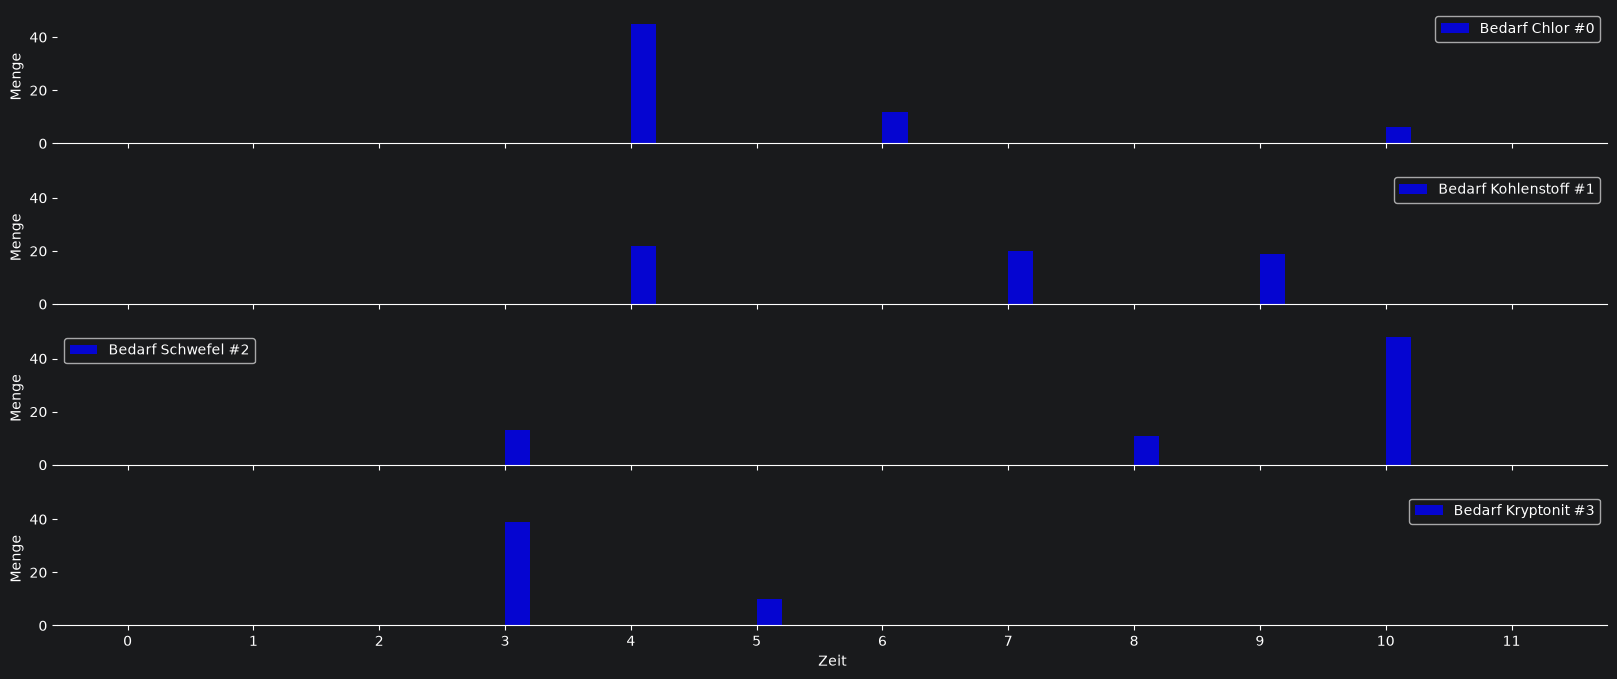

In [11]:
chm.show_demand(inst)

## The model

We begin with the variables

In [12]:
m=mip.Model()
# Zusätzliche Variablen in Periode T, damit p[c][-1] definiert ist
p=[[m.add_var() for _ in range(inst.T+1)] for _ in range(inst.C)]
x=[[[m.add_var() for _ in range(inst.k)] for _ in range(inst.T)] for _ in range(inst.C)]
y=[[[m.add_var(var_type=mip.BINARY) for _ in range(inst.k)] for _ in range(inst.T)] for _ in range(inst.C)]
z=[[m.add_var(var_type=mip.BINARY) for _ in range(inst.k)] for _ in range(inst.T)]

**Implement your MIP here**

In [13]:
# Nothing is in intermediate storage at the start:
for c in range(inst.C):
    m += p[c][inst.T] == 0

for t in range(inst.T):
    # End-of-period inventory cannot exceed storage capacity B:
    m += mip.xsum(p[c][t] for c in range(inst.C)) <= inst.B

    for v in range(inst.k):
        # Transport capacity of any truck cannot be exceeded at any time t:
        m += mip.xsum(x[c][t][v] for c in range(inst.C)) <= inst.h * z[t][v]

        # Implement trip time:
        m += mip.xsum(z[prevT][v] for prevT in range(max(0, t - inst.r), t)) >= inst.r * mip.xsum(y[c][t][v] for c in range(inst.C))
        # Assert: number of periods out of the last r that the truck has been moving    >=  r if the truck is delivering materials right now
        #                                                                               >=  0 else (always true in that case)

        # Dangerous chemicals must not go together:
        for i in inst.I:
            m += y[i[0]][t][v] + y[i[1]][t][v] <= 1

    for c in range(inst.C):
        # Nothing is in intermediate storage at the start:
        m += p[c][inst.T] == 0

        # Demand must be met for every chemical c:
        m += mip.xsum(x[c][t][k] for k in range(inst.k)) + p[c][t-1] >= inst.d[c][t]

        # Delivered amount of each chemical c at every time t must be put in intermediate storage or used:
        m += p[c][t] == p[c][t - 1] + mip.xsum(x[c][t][k] for k in range(inst.k)) - inst.d[c][t]
m.objective = mip.minimize(inst.g * mip.xsum(mip.xsum(z[t][v] for t in range(inst.T)) for v in range(inst.k)) / inst.r)

We start the optimization and print the objectives.

In [14]:
m.verbose=0 # suppress solver output
opt_status=m.optimize()
print("opt status: {}".format(opt_status))
print("Gesamtkosten: {}".format(m.objective_value))

opt status: OptimizationStatus.OPTIMAL
Gesamtkosten: 8.33333333333333


## Graphical Representation

Once again, you can visualize your solutions — this can also help with debugging. By setting the `chemical` parameter to, for example, 1, you can display individual raw materials.

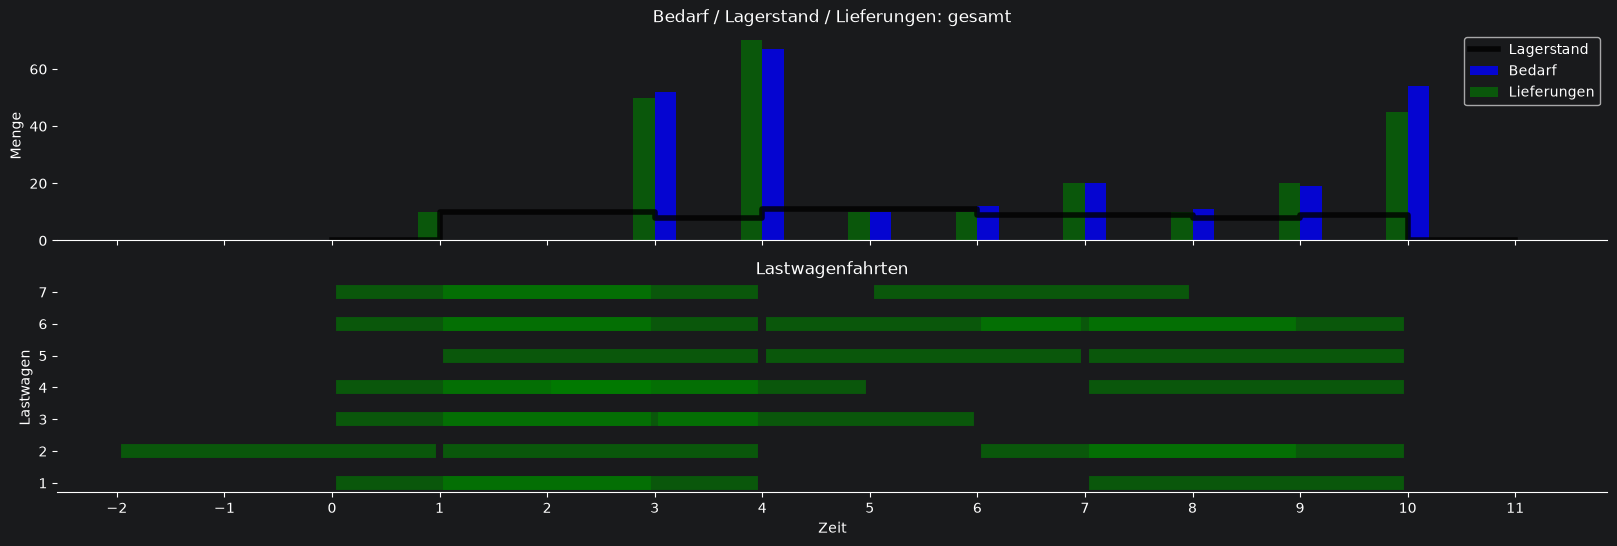

In [15]:
chm.show_solution2(x,z,p,inst,chemical='all')